## Data inspection
Can you predict if an individual will be able to make a payment in an emergency situation?

This notebook covers:
- Loading the data
- Simple EDA and an example of feature engineering
- Data preprocessing and data wrangling
- Creating a simple model
- Making a submission
- Some tips for improving your score

In [129]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
from sklearn.metrics import auc, classification_report, roc_auc_score
from sklearn.model_selection import train_test_split
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
import warnings
warnings.filterwarnings('ignore')

In [4]:
# Load files
train = pd.read_csv('../data/Train.csv')
test = pd.read_csv('../data/Test.csv')
samplesubmission = pd.read_csv('../data/SampleSubmission.csv')
variable_definitions = pd.read_csv('../data/VariableDefinitions.csv')
comments=pd.read_csv('../data/Comments.csv')
competitionPartipation=pd.read_csv('../data/CompetitionPartipation.csv')
competitions=pd.read_csv('../data/Competitions.csv')
discussions=pd.read_csv('../data/Discussions.csv')
submissions=pd.read_csv('../data/Submissions.csv')
users=pd.read_csv('../data/users.csv')
data_list = [train,test,samplesubmission,variable_definitions,comments,competitionPartipation,competitions,discussions,submissions,users]

In [5]:
def analyze(df):
    print('******************************************************************************')
    print(df.head())
    print(df.info())
    print(df.isna().sum())
#     for column in df.columns:
#         if(df[str(column)].dtype== 'int64'):
#             df[str(column)].plot()
#             plt.show()

    print('******************************************************************************')

In [6]:
for frame in data_list:
    analyze(frame)

******************************************************************************
       User_ID  month  year  CompPart  Comment  Sub  Disc  Target
0  ID_XI7BAR4Y      8     3         0        0    0     0       0
1  ID_XI7BAR4Y      8     2         0        0    0     0       0
2  ID_XI7BAR4Y      9     2         0        0    0     0       0
3  ID_XI7BAR4Y      9     3         0        0    0     0       0
4  ID_XI7BAR4Y     10     3         0        0    0     0       0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 259832 entries, 0 to 259831
Data columns (total 8 columns):
 #   Column    Non-Null Count   Dtype 
---  ------    --------------   ----- 
 0   User_ID   259832 non-null  object
 1   month     259832 non-null  int64 
 2   year      259832 non-null  int64 
 3   CompPart  259832 non-null  int64 
 4   Comment   259832 non-null  int64 
 5   Sub       259832 non-null  int64 
 6   Disc      259832 non-null  int64 
 7   Target    259832 non-null  int64 
dtypes: int64(7), object(

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6211 entries, 0 to 6210
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   FeatureF              6211 non-null   int64 
 1   DiscDate Year         6211 non-null   int64 
 2   DiscDate Month        6211 non-null   int64 
 3   DiscDate Day_of_week  6211 non-null   int64 
 4   DiscID                6211 non-null   object
 5   UserID                6211 non-null   object
dtypes: int64(4), object(2)
memory usage: 291.3+ KB
None
FeatureF                0
DiscDate Year           0
DiscDate Month          0
DiscDate Day_of_week    0
DiscID                  0
UserID                  0
dtype: int64
******************************************************************************
******************************************************************************
        UserID  FeatureG   CompID  SubDate Year  SubDate Month  \
0  ID_8JP75F20         1  ID_GFDE           

## INSIGHTS

-Competition_Participation frame has two columns with missing data:

    1.Public Rank
    2.Successful Submission Count
    
-Competitions frame has five columns with missing data:

    1.Country
    2.Feature C
    3.Submission Limit Per Day
    4.CompEndTime Month
    5.CompEndTime Day of Week


In [7]:
def uniques(df):
    for column in df[df.columns]:
        print(column)
        print(df[column].unique())
        print(df[column].nunique())

In [8]:
uniques(competitionPartipation)

CompID
['ID_WMUF' 'ID_MPSN' 'ID_7MLO' 'ID_2KEY' 'ID_50DK' 'ID_AWEI' 'ID_ON5E'
 'ID_QQTZ' 'ID_F53H' 'ID_FBDX' 'ID_D42Y' 'ID_4DT4' 'ID_H4L8' 'ID_UIC7'
 'ID_3JA7' 'ID_1CBJ' 'ID_LQ4P' 'ID_U1HE' 'ID_R5HL' 'ID_HJ9S' 'ID_VNN1'
 'ID_1INW' 'ID_AXVN' 'ID_8PEN' 'ID_G7A4' 'ID_UBMS' 'ID_XWMG' 'ID_ZSZR'
 'ID_XYJZ' 'ID_GCU7' 'ID_JYR6' 'ID_IV8G' 'ID_WGZ2' 'ID_81JW' 'ID_8WX8'
 'ID_SV8O' 'ID_TLNA' 'ID_09D8' 'ID_VS6D' 'ID_IAYS' 'ID_GI2A' 'ID_GTIV'
 'ID_O4PY' 'ID_SAZ4' 'ID_G370' 'ID_Y6XI' 'ID_GQCR' 'ID_FAR8' 'ID_1E58'
 'ID_QXRY' 'ID_LMFN' 'ID_J66M' 'ID_TYYF' 'ID_ABBZ' 'ID_G7MQ' 'ID_P8IG'
 'ID_KG1B' 'ID_N932' 'ID_F7X4' 'ID_DKSX' 'ID_VAQG' 'ID_T638' 'ID_QY5J'
 'ID_V5M1' 'ID_ZBPQ' 'ID_GOXL' 'ID_SW6X' 'ID_88GO' 'ID_E1LI' 'ID_F0B5'
 'ID_3G07' 'ID_G31W' 'ID_664W' 'ID_3HST' 'ID_QCN2' 'ID_D0T1' 'ID_HZ45'
 'ID_VK18' 'ID_HTKR' 'ID_OBP1' 'ID_RSV3' 'ID_VDSL' 'ID_0HHR' 'ID_UWCU'
 'ID_CEI6' 'ID_0G47' 'ID_R4NQ' 'ID_JIF0' 'ID_I5BX' 'ID_WIA6' 'ID_IUTP'
 'ID_YZ4I' 'ID_C59X' 'ID_SNXY' 'ID_MICX' 'ID_DJJ7' 'ID_PH4H' 'ID_I52W'

In [9]:
competitionPartipation.PublicRank.fillna('rank 0',inplace=True)

In [10]:
competitionPartipation['Successful Submission Count'].fillna('count 11',inplace=True)

In [11]:
competitionPartipation.isna().sum()

CompID                         0
UserID                         0
PublicRank                     0
Successful Submission Count    0
CompPartCreated Year           0
CompPartCreated Month          0
CompPartCreated Day_of_week    0
dtype: int64

In [15]:
competitions.isna().sum()

CompID                        0
Country                       0
FeatureA                      0
FeatureB                      0
FeatureC                     17
Kind                          0
Points Reward                 0
FeatureD                      0
SecretCode                    0
SubmissionLimitPerDay         4
FeatureE                      0
CompEndTime Year              0
CompEndTime Month            20
CompEndTime Day_of_week      20
CompStartTime Year            0
CompStartTime Month           0
CompStartTime Day_of_week     0
dtype: int64

In [12]:
uniques(competitions)

CompID
['ID_WGZ2' 'ID_G370' 'ID_R5HL' 'ID_Y6XI' 'ID_8PEN' 'ID_F23U' 'ID_GOXL'
 'ID_88GO' 'ID_HTKR' 'ID_ABBZ' 'ID_ASHZ' 'ID_LXXE' 'ID_I52W' 'ID_TKJJ'
 'ID_57TX' 'ID_ZBPQ' 'ID_SNXY' 'ID_GTIV' 'ID_P8IG' 'ID_GQCR' 'ID_BQO2'
 'ID_4FPW' 'ID_664W' 'ID_GCU7' 'ID_5B6Q' 'ID_JIF0' 'ID_LMFN' 'ID_G31W'
 'ID_HJ9S' 'ID_RSV3' 'ID_R4NQ' 'ID_SW6X' 'ID_5HIG' 'ID_1FDX' 'ID_JQS3'
 'ID_92AG' 'ID_3HST' 'ID_BT9Z' 'ID_18R6' 'ID_3HLK' 'ID_UIC7' 'ID_CKLY'
 'ID_4DT4' 'ID_JYR6' 'ID_0HHR' 'ID_TLNA' 'ID_YXS6' 'ID_AWEI' 'ID_50Y5'
 'ID_F53H' 'ID_QXRY' 'ID_TL9O' 'ID_AXVN' 'ID_VNW7' 'ID_VS6D' 'ID_H4L8'
 'ID_TIK1' 'ID_3G07' 'ID_V5M1' 'ID_HZ45' 'ID_OBP1' 'ID_WIA6' 'ID_QCN2'
 'ID_LQ4P' 'ID_GI2A' 'ID_F0B5' 'ID_VDSL' 'ID_Y20Y' 'ID_T638' 'ID_S3FU'
 'ID_O4PY' 'ID_VNN1' 'ID_EZD0' 'ID_UWCU' 'ID_3XEN' 'ID_3JA7' 'ID_58T1'
 'ID_ZSZR' 'ID_1E58' 'ID_IUTP' 'ID_92VT' 'ID_DJJ7' 'ID_1INW' 'ID_IV8G'
 'ID_1CBJ' 'ID_SIY6' 'ID_D0T1' 'ID_XWMG' 'ID_QQTZ' 'ID_YZ4I' 'ID_81JW'
 'ID_SV8O' 'ID_DKSX' 'ID_7MLO' 'ID_U1HE' 'ID_TYYF' 'ID_8WX8' 'ID_85VQ'

In [14]:
competitions['Country'].fillna('ID_XXXX',inplace=True)

In [16]:
competitions['FeatureC'].fillna('40',inplace=True)

In [21]:
competitions['CompEndTime Month'].fillna(3,inplace=True)

In [23]:
competitions['CompEndTime Day_of_week'].fillna(6,inplace=True)

In [26]:
competitions['SubmissionLimitPerDay'].fillna(200,inplace=True)

In [24]:
competitionPartipation.isna().sum()

CompID                         0
UserID                         0
PublicRank                     0
Successful Submission Count    0
CompPartCreated Year           0
CompPartCreated Month          0
CompPartCreated Day_of_week    0
dtype: int64

In [28]:
competitions.isna().sum()

CompID                       0
Country                      0
FeatureA                     0
FeatureB                     0
FeatureC                     0
Kind                         0
Points Reward                0
FeatureD                     0
SecretCode                   0
SubmissionLimitPerDay        0
FeatureE                     0
CompEndTime Year             0
CompEndTime Month            0
CompEndTime Day_of_week      0
CompStartTime Year           0
CompStartTime Month          0
CompStartTime Day_of_week    0
dtype: int64

In [35]:
comments.columns

Index(['UserID', 'CommentDate Year', 'CommentDate Month',
       'CommentDate Day_of_week'],
      dtype='object')

In [36]:
comments.columns = ['User_ID', 'year', 'month',
       'day']

In [37]:
discussions.columns

Index(['FeatureF', 'DiscDate Year', 'DiscDate Month', 'DiscDate Day_of_week',
       'DiscID', 'UserID'],
      dtype='object')

In [38]:
discussions.columns = ['FeatureF', 'year', 'month', 'day',
       'Disc_ID', 'User_ID']

In [39]:
submissions.columns

Index(['UserID', 'FeatureG', 'CompID', 'SubDate Year', 'SubDate Month',
       'SubDate Day_of_week'],
      dtype='object')

In [40]:
submissions.columns = ['User_ID', 'FeatureG', 'Competition_ID', 'year', 'month',
       'day']

In [41]:
competitionPartipation.columns

Index(['CompID', 'UserID', 'PublicRank', 'Successful Submission Count',
       'CompPartCreated Year', 'CompPartCreated Month',
       'CompPartCreated Day_of_week'],
      dtype='object')

In [42]:
competitionPartipation.columns = ['Competition_ID', 'User_ID', 'PublicRank', 'Successful_Submission_Count',
       'year_part', 'month_part',
       'day_joined']

In [43]:
competitions.columns

Index(['CompID', 'Country', 'FeatureA', 'FeatureB', 'FeatureC', 'Kind',
       'Points Reward', 'FeatureD', 'SecretCode', 'SubmissionLimitPerDay',
       'FeatureE', 'CompEndTime Year', 'CompEndTime Month',
       'CompEndTime Day_of_week', 'CompStartTime Year', 'CompStartTime Month',
       'CompStartTime Day_of_week'],
      dtype='object')

In [44]:
competitions.columns = ['Competition_ID', 'Country', 'FeatureA', 'FeatureB', 'FeatureC', 'Kind',
       'Points_Reward', 'FeatureD', 'SecretCode', 'SubmissionLimitPerDay',
       'FeatureE', 'end_year', 'end_month',
       'end_day', 'start_year', 'start_month',
       'start_day']

In [47]:
users.columns

Index(['User_ID', 'FeatureX', 'Country', 'FeatureY', 'Points', 'year_joined',
       'month_joined', 'day_joined'],
      dtype='object')

In [46]:
users.columns = ['User_ID', 'FeatureX', 'Country', 'FeatureY', 'Points', 'year_joined',
       'month_joined', 'day_joined']

In [53]:
grouped_comments= comments.groupby(['User_ID','year','month']).count().reset_index()

In [131]:
grouped_comments.columns

Index(['User_ID', 'year', 'month', 'day'], dtype='object')

In [54]:
grouped_discussions = discussions.groupby(['User_ID','year','month','FeatureF']).count().reset_index()

In [132]:
grouped_discussions.columns

Index(['User_ID', 'year', 'month', 'FeatureF', 'discussion_count'], dtype='object')

In [55]:
grouped_discussions.drop('day',axis=1,inplace=True)

In [56]:
grouped_discussions.rename(columns={'Disc_ID':'discussion_count'},inplace=True)

In [57]:
submissions_grouped = submissions.groupby(['User_ID','Competition_ID','year','month','FeatureG']).count().reset_index()

In [58]:
submissions_grouped.rename(columns={'day':'submission_count'},inplace=True)

In [81]:
grouped_discussions.drop_duplicates(['User_ID','year','month'],inplace=True)

In [59]:
submission_competition_merge = submissions_grouped.merge(competitions,how='left',on=['Competition_ID'])

In [60]:
submission_competition_merge.head()

,User_ID,Competition_ID,year,month,FeatureG,submission_count,Country,FeatureA,FeatureB,FeatureC,...,FeatureD,SecretCode,SubmissionLimitPerDay,FeatureE,end_year,end_month,end_day,start_year,start_month,start_day
0,ID_000VV0KM,ID_F53H,2,12,0,3,ID_HWRH,"[3, 2]",[14],1.0,...,2,0,30.0,[2],3,2.0,6.0,2,11,6
1,ID_000VV0KM,ID_F53H,2,12,1,2,ID_HWRH,"[3, 2]",[14],1.0,...,2,0,30.0,[2],3,2.0,6.0,2,11,6
2,ID_000VV0KM,ID_H4L8,2,12,1,2,ID_60OO,"[1, 4, 5]","[5, 7]",40,...,2,0,30.0,[7],2,12.0,6.0,2,7,7
3,ID_00HKNVC0,ID_C59X,3,3,1,2,ID_5OWN,[1],[],33.0,...,3,1,10.0,[1],3,3.0,5.0,3,3,5
4,ID_00HKNVC0,ID_GFDE,3,3,1,5,ID_5OWN,[1],[],25.0,...,3,1,10.0,[1],3,3.0,5.0,3,3,5


In [82]:
submission_competition_merge.drop_duplicates(['User_ID','year','month'],inplace=True)

In [50]:
train.drop(['CompPart', 'Comment', 'Sub', 'Disc'],axis=1,inplace=True)

In [51]:
train.columns

Index(['User_ID', 'month', 'year', 'Target'], dtype='object')

In [52]:
test.columns

Index(['User_ID', 'month', 'year'], dtype='object')

In [90]:
ntrain = train.shape[0]
all_data = pd.concat((train, test)).reset_index(drop=True)

In [91]:
all_data.shape

(325055, 4)

In [138]:
df = all_data.merge(grouped_comments,on=['User_ID','year','month'],how='left').merge(grouped_discussions,on=['User_ID','year','month'],how='left').merge(submission_competition_merge,on=['User_ID','year','month'],how='left')

In [85]:
all_data.merge(grouped_comments,on=['User_ID','year','month'],how='left').merge(grouped_discussions,on=['User_ID','year','month'],how='left').merge(submission_competition_merge,on=['User_ID','year','month'],how='left').isna().sum()

User_ID                       0
month                         0
year                          0
Target                    65223
day                      321206
FeatureF                 321279
discussion_count         321279
Competition_ID           308253
FeatureG                 308253
submission_count         308253
Country                  308253
FeatureA                 308253
FeatureB                 308253
FeatureC                 308253
Kind                     308253
Points_Reward            308253
FeatureD                 308253
SecretCode               308253
SubmissionLimitPerDay    308253
FeatureE                 308253
end_year                 308253
end_month                308253
end_day                  308253
start_year               308253
start_month              308253
start_day                308253
dtype: int64

In [87]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 325055 entries, 0 to 325054
Data columns (total 26 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   User_ID                325055 non-null  object 
 1   month                  325055 non-null  int64  
 2   year                   325055 non-null  int64  
 3   Target                 259832 non-null  float64
 4   day                    3849 non-null    float64
 5   FeatureF               3776 non-null    float64
 6   discussion_count       3776 non-null    float64
 7   Competition_ID         16802 non-null   object 
 8   FeatureG               16802 non-null   float64
 9   submission_count       16802 non-null   float64
 10  Country                16802 non-null   object 
 11  FeatureA               16802 non-null   object 
 12  FeatureB               16802 non-null   object 
 13  FeatureC               16802 non-null   object 
 14  Kind                   16802 non-nul

In [139]:
num = ['discussion_count','submission_count','Points_Reward','SubmissionLimitPerDay']
cat = ['day','FeatureF','Country','FeatureG','FeatureA','FeatureB','FeatureC','Kind','FeatureD','SecretCode','FeatureE','end_year','end_month','end_day','start_year','start_month','start_day']

In [140]:
# Fill in missing values
# For cat cols and date cols fill in with mode and for num cols fill in with 9999
for col in df.columns:
  if col in cat:
    df[col] = df[col].fillna(df[col].mode()[0])
  elif col in num:
    df[col] = df[col].fillna(df[col].fillna(0))

# Confirm that there aren't any missing values
df[df.columns.difference(['target'])].isna().sum().any()

True

In [141]:
df.isna().sum()

User_ID                       0
month                         0
year                          0
Target                    65223
day                           0
FeatureF                      0
discussion_count              0
Competition_ID           308253
FeatureG                      0
submission_count              0
Country                       0
FeatureA                      0
FeatureB                      0
FeatureC                      0
Kind                          0
Points_Reward                 0
FeatureD                      0
SecretCode                    0
SubmissionLimitPerDay         0
FeatureE                      0
end_year                      0
end_month                     0
end_day                       0
start_year                    0
start_month                   0
start_day                     0
dtype: int64

In [142]:
# Separate train and test data from the combined dataframe
train_df = df[:ntrain]
test_df = df[ntrain:]

# Check the shapes of the split dataset
train_df.shape, test_df.shape

((259832, 26), (65223, 26))

In [96]:
train_df.columns

Index(['User_ID', 'month', 'year', 'Target', 'day', 'FeatureF',
       'discussion_count', 'Competition_ID', 'FeatureG', 'submission_count',
       'Country', 'FeatureA', 'FeatureB', 'FeatureC', 'Kind', 'Points_Reward',
       'FeatureD', 'SecretCode', 'SubmissionLimitPerDay', 'FeatureE',
       'end_year', 'end_month', 'end_day', 'start_year', 'start_month',
       'start_day'],
      dtype='object')

In [149]:
# class count
class_count_0, class_count_1 = train_df['Target'].value_counts()

# Separate class
class_0 = train_df[train_df['Target'] == 0]
class_1 = train_df[train_df['Target'] == 1]# print the shape of the class
print('class 0:', class_0.shape)
print('class 1:', class_1.shape)

class 0: (223526, 26)
class 1: (36306, 26)


total class of 1 and0: 0.0    36306
1.0    36306
Name: Target, dtype: int64


<AxesSubplot:title={'center':'count (target)'}>

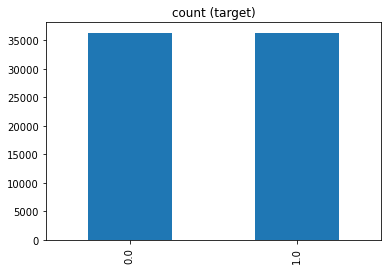

In [151]:
class_0_under = class_0.sample(class_count_1)

test_under = pd.concat([class_0_under, class_1], axis=0)

print("total class of 1 and0:",test_under['Target'].value_counts())# plot the count after under-sampeling
test_under['Target'].value_counts().plot(kind='bar', title='count (target)')

total class of 1 and 0: 0.0    36306
1.0    36306
Name: Target, dtype: int64


<AxesSubplot:title={'center':'count (target)'}>

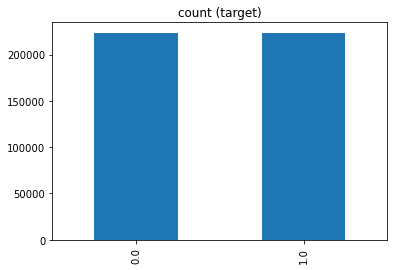

In [156]:
class_1_over = class_1.sample(class_count_0, replace=True)

test_over = pd.concat([class_1_over, class_0], axis=0)

print("total class of 1 and 0:",test_under['Target'].value_counts())# plot the count after under-sampeling
test_over['Target'].value_counts().plot(kind='bar', title='count (target)')

In [157]:
test_over.head()

,User_ID,month,year,Target,day,FeatureF,discussion_count,Competition_ID,FeatureG,submission_count,...,FeatureD,SecretCode,SubmissionLimitPerDay,FeatureE,end_year,end_month,end_day,start_year,start_month,start_day
120338,ID_NRGSUSMU,12,3,1.0,1.0,0.0,0.0,ID_R5HL,0.0,1.0,...,2.0,0.0,10.0,[1],4,1.0,6.0,3.0,10.0,4.0
220141,ID_801089G1,2,3,1.0,1.0,0.0,0.0,NaN,1.0,0.0,...,2.0,0.0,0.0,[1],3,3.0,6.0,3.0,4.0,4.0
60076,ID_XS7PJHVK,3,3,1.0,1.0,0.0,0.0,ID_ZSZR,1.0,1.0,...,2.0,0.0,30.0,[1],3,4.0,6.0,3.0,2.0,2.0
259813,ID_NH5HZ15A,12,3,1.0,1.0,0.0,1.0,NaN,1.0,0.0,...,2.0,0.0,0.0,[1],3,3.0,6.0,3.0,4.0,4.0
46918,ID_2C4U2R8P,11,3,1.0,2.0,1.0,2.0,ID_HTKR,0.0,1.0,...,3.0,0.0,30.0,[2],not mapped,3.0,6.0,3.0,2.0,3.0


In [133]:
select = ['month', 'year','discussion_count','day', 'submission_count','Points_Reward', 'SubmissionLimitPerDay', 'end_month', 'start_year', 'start_month']

In [158]:
# Select main columns to be used in training
x=test_over[select]
y=test_over.Target.astype(int)

In [135]:
train_df[select].info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 259832 entries, 0 to 259831
Data columns (total 5 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   month             259832 non-null  int64  
 1   year              259832 non-null  int64  
 2   discussion_count  259832 non-null  float64
 3   day               259832 non-null  float64
 4   submission_count  259832 non-null  float64
dtypes: float64(3), int64(2)
memory usage: 11.9 MB


In [159]:

# Split data into train and test sets
# X_train, X_test, y_train, y_test = train_test_split(x,y,test_size=0.3, random_state=42)

# Train model
model = RandomForestClassifier()
model.fit(x, y)

# Make predictions
y_pred = model.predict(test_df[select])

# Check the auc score of the model
# print(f'RandomForest AUC score on the X_test is: {roc_auc_score(y_test, y_pred)}\n')

# print classification report
# print(classification_report(y_test, [1 if x >= 0.5 else 0 for x in y_pred]))

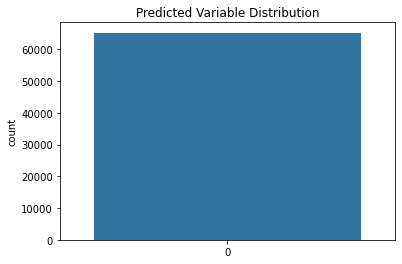

In [160]:
# # Make prediction on the test set
# test_df = test_df[select]
# result = model.predict(test_df[select])
result=pd.DataFrame(y_pred)



# # Create a submission file
result['UserMonthYear'] = test['User_ID'].astype(str)+'_'+test['month'].astype(str)+'_'+test['year'].astype(str)
result = np.fliplr(result)
result=pd.DataFrame(result)
result.columns=['UserMonthYear','Target']




# # Check the distribution of your predictions
sns.countplot([1 if x >= 0.5 else 0 for x in result.Target])
plt.title('Predicted Variable Distribution');

In [146]:
# Create a csv file and upload to zindi 
result.to_csv('Baseline.csv', index = False)
result.head()

,UserMonthYear,Target
0,ID_H1ELY25E_1_4,0
1,ID_H1ELY25E_2_4,0
2,ID_H1ELY25E_3_4,0
3,ID_463Q2BCO_1_4,0
4,ID_463Q2BCO_2_4,0


In [124]:
result.Target.unique()

array([0], dtype=object)